# Part A — the metrics that survive imbalance

Companion notebook to **"Why Your Churn Model Is Not a Risk Model (And Why It Matters)"**.

Plain Jupyter, plain scikit-learn, no dependency on the rest of this repo. It runs in
about twenty seconds and it makes four claims from the article checkable by hand:

1. At fraud-level imbalance, accuracy is not a weak metric. It is an actively misleading one.
2. ROC-AUC flatters. PR-AUC does not.
3. Precision at *k*, where *k* is the number of cases your team can actually work.
4. The block threshold is a cost calculation, it comes out at 0.77 rather than 0.5,
   and it is only meaningful if the probabilities are calibrated where the decision happens.

Everything is seeded, so the numbers below are the numbers you will get.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, average_precision_score,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import train_test_split

SEED = 7
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.15, 'font.size': 9})
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#52514e'

## A dataset with a fraud-shaped class balance

One in a thousand is fraud. Fraudulent rows differ on three signals — velocity, a new
device, and an amount out of line with the account's history — but they overlap the
legitimate population heavily, because in real data they do.

In [2]:
N = 400_000
FRAUD_RATE = 0.002                       # 1 in 500; the article's range is 0.1% to 1%

is_fraud = rng.random(N) < FRAUD_RATE
n_fraud = int(is_fraud.sum())

X = pd.DataFrame({
    'txn_60s':      rng.poisson(np.where(is_fraud, 4.0, 0.25)),
    'new_device':   rng.random(N) < np.where(is_fraud, 0.75, 0.03),
    'amount_ratio': np.exp(rng.normal(np.where(is_fraud, 1.2, 0.0), 0.7)),
    'hour':         rng.integers(0, 24, N),
}).astype(float)
y = is_fraud.astype(int)

print(f'{N:,} transactions, {n_fraud:,} of them fraud ({y.mean():.3%})')

400,000 transactions, 775 of them fraud (0.194%)


## 1. Accuracy at 0.1% positives

The comparison worth doing first is against a model that does nothing at all.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)

model = CalibratedClassifierCV(
    HistGradientBoostingClassifier(random_state=SEED, max_iter=200),
    method='isotonic', cv=3).fit(X_tr, y_tr)
p = model.predict_proba(X_te)[:, 1]

never = np.zeros_like(y_te)                    # predicts 'not fraud', always
at_half = (p >= 0.5).astype(int)

print(f"accuracy of a model that says 'never fraud': {accuracy_score(y_te, never):.4%}")
print(f'accuracy of the trained model at 0.5:        {accuracy_score(y_te, at_half):.4%}')
print(f'\nthe do-nothing model catches {never.sum()} of {y_te.sum()} frauds.')

accuracy of a model that says 'never fraud': 99.8062%
accuracy of the trained model at 0.5:        99.9237%

the do-nothing model catches 0 of 310 frauds.


The null model is 99.9% accurate and worth nothing. Any metric that ranks it near the
top of the leaderboard is not measuring the thing you care about.

## 2. ROC-AUC flatters, PR-AUC does not

In [4]:
base = y_te.mean()
pr_auc = average_precision_score(y_te, p)
print(f'ROC-AUC: {roc_auc_score(y_te, p):.3f}   (a coin flip scores 0.500)')
print(f'PR-AUC:  {pr_auc:.3f}   (random scores the base rate, {base:.4f})')
print(f'\nlift over random: {pr_auc / base:.0f}x')

ROC-AUC: 0.977   (a coin flip scores 0.500)
PR-AUC:  0.812   (random scores the base rate, 0.0019)

lift over random: 419x


ROC-AUC divides false positives by the size of the negative class. With 199,800
negatives, a thousand false positives move the false positive rate by half a
percentage point, so ROC-AUC stays high through a decision that would put a thousand
good customers through a declined payment. PR-AUC prices the same mistake against the
positives, which is the population you are actually trying to find.

## 3. Precision at k, where k is your capacity

Nobody reviews a ranking. They review the top of it, as far down as the team can get.

In [5]:
def precision_at_k(y_true, score, k):
    top = np.argsort(score)[::-1][:k]
    return np.asarray(y_true)[top].mean()

def recall_at_k(y_true, score, k):
    top = np.argsort(score)[::-1][:k]
    return np.asarray(y_true)[top].sum() / np.sum(y_true)

rows = [{'k (cases reviewed)': k,
         'precision@k': precision_at_k(y_te, p, k),
         'recall@k': recall_at_k(y_te, p, k),
         'lift vs random': precision_at_k(y_te, p, k) / base}
        for k in (25, 50, 100, 250, 500)]
pd.DataFrame(rows).style.format({'precision@k': '{:.1%}', 'recall@k': '{:.1%}',
                                 'lift vs random': '{:.0f}x'})

,k (cases reviewed),precision@k,recall@k,lift vs random
0,25,100.0%,8.1%,516x
1,50,100.0%,16.1%,516x
2,100,99.0%,31.9%,511x
3,250,86.8%,70.0%,448x
4,500,51.6%,83.2%,266x


## 4. Calibration, and why the threshold depends on it

The article's arithmetic: block when the expected cost of allowing exceeds the expected
cost of blocking.

$$p \\times \\$150 > (1-p) \\times \\$500 \\quad\\Longrightarrow\\quad p > \\frac{500}{500+150} = 0.77$$

That step treats $p$ as a real probability. If the model's 0.7 is really 0.9, the
threshold is wrong by an amount nobody will notice.

In [6]:
FP_COST, FN_COST = 500, 150
threshold = FP_COST / (FP_COST + FN_COST)
print(f'threshold from the costs: {threshold:.3f}')

def total_cost(t):
    acted = p >= t
    return ((acted & (y_te == 0)).sum() * FP_COST
            + (~acted & (y_te == 1)).sum() * FN_COST)

grid = np.linspace(0.01, 0.99, 99)
costs = np.array([total_cost(t) for t in grid])
best = grid[costs.argmin()]

print(f'cost at 0.50:              ${total_cost(0.50):>9,.0f}')
print(f'cost at {threshold:.2f} (from costs): ${total_cost(threshold):>9,.0f}')
print(f'cost at {best:.2f} (measured):    ${costs.min():>9,.0f}')

threshold from the costs: 0.769
cost at 0.50:              $   23,200
cost at 0.77 (from costs): $   30,500
cost at 0.58 (measured):    $   23,000


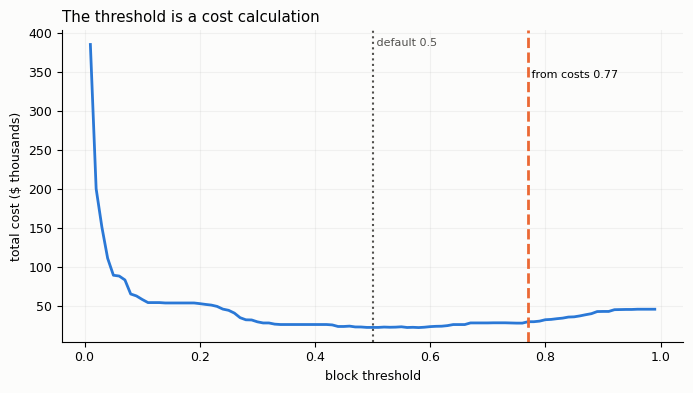

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, costs / 1000, color=BLUE, lw=2)
ax.axvline(0.5, color=GREY, ls=':', lw=1.5)
ax.text(0.5, ax.get_ylim()[1] * 0.95, ' default 0.5', color=GREY, fontsize=8)
ax.axvline(threshold, color=ORANGE, ls='--', lw=2)
ax.text(threshold, ax.get_ylim()[1] * 0.85, f' from costs {threshold:.2f}', fontsize=8)
ax.set_xlabel('block threshold'); ax.set_ylabel('total cost ($ thousands)')
ax.set_title('The threshold is a cost calculation', loc='left')
plt.tight_layout(); plt.show()

### Check the calibration where the decision happens

A single expected-calibration-error number over the whole test set is dominated by the
199,800 rows sitting at $p \\approx 0$. Those rows are not where any decision gets made.

In [8]:
def ece(y_true, prob, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(prob, edges[1:-1]), 0, bins - 1)
    out = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            out += m.mean() * abs(prob[m].mean() - np.asarray(y_true)[m].mean())
    return out

region = p >= 0.05
print(f'ECE over everything:                       {ece(y_te, p):.4f}')
print(f'ECE over the decision region (p >= 0.05):  {ece(y_te[region], p[region]):.4f}')
print(f'                                           ({region.sum():,} rows)')

lo, hi = min(best, threshold), max(best, threshold)
band = (p >= lo) & (p < hi)
if band.sum():
    print(f'\nrows scored between {lo:.2f} and {hi:.2f}: {band.sum():,}')
    print(f'  the model says they are {p[band].mean():.0%} likely to be fraud')
    print(f'  they are actually        {y_te[band].mean():.0%} fraud')

ECE over everything:                       0.0006
ECE over the decision region (p >= 0.05):  0.1386
                                           (412 rows)

rows scored between 0.58 and 0.77: 63
  the model says they are 67% likely to be fraud
  they are actually        95% fraud


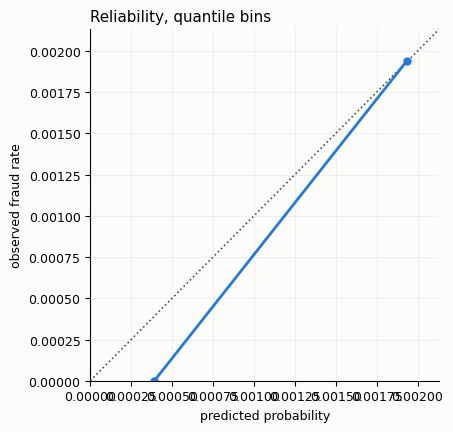

In [9]:
# Reliability diagram, on quantile bins so the plot is about the scores that matter
edges = np.unique(np.quantile(p, np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf
idx = np.digitize(p, edges[1:-1])
pred, obs = [], []
for b in range(len(edges) - 1):
    m = idx == b
    if m.sum() >= 5:
        pred.append(p[m].mean()); obs.append(y_te[m].mean())

lim = max(max(pred), max(obs)) * 1.1
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, lim], [0, lim], color=GREY, ls=':', lw=1.2)
ax.plot(pred, obs, marker='o', color=BLUE, lw=2, ms=5)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('predicted probability'); ax.set_ylabel('observed fraud rate')
ax.set_title('Reliability, quantile bins', loc='left')
plt.tight_layout(); plt.show()

## 5. What the bands are for

The block threshold has to stay high to protect the insult rate, which leaves real fraud
underneath it. That is what the challenge and review bands are for: cheaper actions for
scores that do not justify a decline.

In [10]:
BANDS = {'challenge': 0.30, 'review': 0.60}

def decide(prob):
    if prob >= threshold: return 'block'
    if prob >= BANDS['review']: return 'review'
    if prob >= BANDS['challenge']: return 'challenge'
    return 'allow'

decisions = pd.Series([decide(v) for v in p], name='decision')
mix = pd.crosstab(decisions, pd.Series(y_te, name='is_fraud'))
print(mix.to_string())

legit = y_te == 0
insult = ((p >= threshold) & legit).sum() / legit.sum()
blocked = ((p >= threshold) & (y_te == 1)).sum() / (y_te == 1).sum()
touched = ((p >= BANDS['challenge']) & (y_te == 1)).sum() / (y_te == 1).sum()
print(f'\ninsult rate (good customers blocked): {insult:.4%}')
print(f'fraud blocked outright:               {blocked:.1%}')
print(f'fraud challenged, reviewed or blocked:{touched:.1%}')

is_fraud        0    1
decision              
allow      159656   89
block           1  110
challenge      30   59
review          3   52

insult rate (good customers blocked): 0.0006%
fraud blocked outright:               35.5%
fraud challenged, reviewed or blocked:71.3%


## What this notebook cannot show

Everything above works on one static table, which is exactly the limitation the article
warns about. A shuffled `train_test_split` on fraud data is not a valid evaluation, and
it is used here only because this notebook is about metrics rather than about validation.

The pieces that need a time axis live in the scripts at the repo root:

| Claim | Where |
| :--- | :--- |
| Labels arrive 30–90 days late, and what training without them costs | `02_risk_realtime_pipeline.py` |
| Out-of-time validation against the shuffled split that flatters it | `02_risk_realtime_pipeline.py` |
| Point-in-time features, and what leakage buys offline | `01_churn_batch_pipeline.py` |
| Blocking erases the outcome (selective labels) | `04_feedback_loops.py` |
| The retention call erases the label | `04_feedback_loops.py` |
| Monitoring that fires 89 days before the labels can | `05_monitoring_two_clocks.py` |

And `part_b_databricks.py` has the platform version of all of it.